In [83]:
import matplotlib.pyplot as plt
import numpy as np

# Ex 1
with open("Detroit.txt") as f:
    lines = f.readlines()

header_idx = next(
    i for i, line in enumerate(lines)
    if line.strip().startswith("FTP") and "UEMP" in line
)

variables = lines[header_idx].split()

X = np.loadtxt("Detroit.txt", skiprows=header_idx + 1)

print("Shape:", X.shape)
print("Variables:", variables)
print("First five rows:\n", X[:5])

Shape: (13, 14)
Variables: ['FTP', 'UEMP', 'MAN', 'LIC', 'GR', 'CLEAR', 'WM', 'NMAN', 'GOV', 'HE', 'WE', 'HOM', 'ACC', 'ASR']
First five rows:
 [[2.60350e+02 1.10000e+01 4.55500e+02 1.78150e+02 2.15980e+02 9.34000e+01
  5.58724e+05 5.38100e+02 1.33900e+02 2.98000e+00 1.17180e+02 8.60000e+00
  3.91700e+01 3.06180e+02]
 [2.69800e+02 7.00000e+00 4.80200e+02 1.56410e+02 1.80480e+02 8.85000e+01
  5.38584e+05 5.47600e+02 1.37600e+02 3.09000e+00 1.34020e+02 8.90000e+00
  4.02700e+01 3.15160e+02]
 [2.72040e+02 5.20000e+00 5.06100e+02 1.98020e+02 2.09570e+02 9.44000e+01
  5.19171e+05 5.62800e+02 1.43600e+02 3.23000e+00 1.41680e+02 8.52000e+00
  4.53100e+01 2.77530e+02]
 [2.72960e+02 4.30000e+00 5.35800e+02 2.22100e+02 2.31670e+02 9.20000e+01
  5.00457e+05 5.91000e+02 1.50300e+02 3.33000e+00 1.47980e+02 8.89000e+00
  4.95100e+01 2.34070e+02]
 [2.72510e+02 3.50000e+00 5.76000e+02 3.01920e+02 2.97650e+02 9.10000e+01
  4.82418e+05 6.26100e+02 1.64300e+02 3.46000e+00 1.59850e+02 1.30700e+01
  5.5050

In [84]:
X_centered = X - np.mean(X, axis=0)

S = np.cov(X_centered, rowvar=False)

eigenvalues, eigenvectors = np.linalg.eigh(S)

print("S shape:", S.shape)
print("Eigenvalues:", eigenvalues)

S shape: (14, 14)
Eigenvalues: [-1.21718399e-13  3.44269177e-08  1.01359958e-01  3.99093796e-01
  2.58335741e+00  6.30047967e+00  1.59532307e+01  5.92990252e+01
  1.04855146e+02  4.76830970e+02  3.18591840e+03  9.61698806e+03
  5.79992410e+04  4.16919065e+09]


In [85]:
idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

explained_variance = eigenvalues / np.sum(eigenvalues)

cumulative_variance = np.cumsum(explained_variance)

for i, variance in enumerate(cumulative_variance):
    print(f"{i+1} PCs: {variance:.6%}")

k80 = np.searchsorted(cumulative_variance, 0.80) + 1
k90 = np.searchsorted(cumulative_variance, 0.90) + 1

print("PCs for 80%:", k80)
print("PCs for 90%:", k90)

1 PCs: 99.998286%
2 PCs: 99.999677%
3 PCs: 99.999908%
4 PCs: 99.999984%
5 PCs: 99.999995%
6 PCs: 99.999998%
7 PCs: 99.999999%
8 PCs: 100.000000%
9 PCs: 100.000000%
10 PCs: 100.000000%
11 PCs: 100.000000%
12 PCs: 100.000000%
13 PCs: 100.000000%
14 PCs: 100.000000%
PCs for 80%: 1
PCs for 90%: 1


In [86]:
k = k90

V_k = eigenvectors[:, :k]
Y = X_centered @ V_k

print("Principal components shape:", Y.shape)
print("Principal component scores:\n", Y)

Principal components shape: (13, 1)
Principal component scores:
 [[-106217.65409818]
 [ -86078.18629021]
 [ -66665.23510682]
 [ -47951.35004486]
 [ -29912.0071357 ]
 [ -12522.63225549]
 [   4241.22243806]
 [  20402.45297766]
 [  35976.18425908]
 [  50990.49897966]
 [  65462.52257514]
 [  79413.63740543]
 [  92860.54629623]]


In [87]:
correlations = np.corrcoef(X.T, Y.T)[:X.shape[1], X.shape[1]:]

for name, corr in zip(variables, correlations[:, 0]):
    print(f"{name}: {corr:.4f}")

FTP: 0.8839
UEMP: -0.0731
MAN: 0.7528
LIC: 0.7837
GR: 0.8458
CLEAR: -0.8906
WM: -1.0000
NMAN: 0.9943
GOV: 0.9886
HE: 0.8667
WE: 0.8603
HOM: 0.9526
ACC: 0.0756
ASR: 0.6531


In [88]:
Z = (X - X.mean(axis=0)) / X.std(axis=0, ddof=1)

S_z = np.cov(Z, rowvar=False)

eigenvalues_z, eigenvectors_z = np.linalg.eigh(S_z)

idx = np.argsort(eigenvalues_z)[::-1]
eigenvalues_z = eigenvalues_z[idx]
eigenvectors_z = eigenvectors_z[:, idx]

explained_z = eigenvalues_z / eigenvalues_z.sum()
cumulative_z = np.cumsum(explained_z)

for i, variance in enumerate(cumulative_z):
    print(f"{i+1} PCs: {variance:.6%}")

k80_z = np.searchsorted(cumulative_z, 0.80) + 1
k90_z = np.searchsorted(cumulative_z, 0.90) + 1

print("PCs for 80%:", k80_z)
print("PCs for 90%:", k90_z)

1 PCs: 68.583969%
2 PCs: 90.638887%
3 PCs: 96.715434%
4 PCs: 98.272780%
5 PCs: 98.931743%
6 PCs: 99.343032%
7 PCs: 99.646444%
8 PCs: 99.802123%
9 PCs: 99.939684%
10 PCs: 99.985293%
11 PCs: 99.997043%
12 PCs: 100.000000%
13 PCs: 100.000000%
14 PCs: 100.000000%
PCs for 80%: 2
PCs for 90%: 2


In [89]:
k = k90_z
V_k_z = eigenvectors_z[:, :k]

Y_z = Z @ V_k_z

print("Principal components shape:", Y_z.shape)
print("Principal component scores:\n", Y_z)

correlations_z = np.corrcoef(X.T, Y_z.T)[:X.shape[1], X.shape[1]:]

print("\nCorrelations:")
for name, corr in zip(variables, correlations_z):
    print(f"{name:6s} PC1: {corr[0]: .4f}  PC2: {corr[1]: .4f}")

Principal components shape: (13, 2)
Principal component scores:
 [[ 3.81266544  3.16041727]
 [ 3.29992982  2.08722453]
 [ 3.18418773  0.64927661]
 [ 2.8394824  -0.4774624 ]
 [ 2.08073994 -1.72984271]
 [ 1.49602652 -2.12465088]
 [ 0.47186596 -1.43903892]
 [-0.4585438  -2.32942717]
 [-1.64743442 -1.54329216]
 [-2.19114016  0.10713261]
 [-3.32135034  1.08678315]
 [-4.40366091  1.60923336]
 [-5.1627682   0.9436467 ]]

Correlations:
FTP    PC1: -0.9533  PC2:  0.2371
UEMP   PC1: -0.1117  PC2:  0.9152
MAN    PC1: -0.6240  PC2: -0.7512
LIC    PC1: -0.7313  PC2: -0.4114
GR     PC1: -0.8287  PC2: -0.2342
CLEAR  PC1:  0.9566  PC2: -0.2338
WM     PC1:  0.9760  PC2:  0.2016
NMAN   PC1: -0.9784  PC2: -0.1799
GOV    PC1: -0.9734  PC2: -0.1576
HE     PC1: -0.9196  PC2:  0.2075
WE     PC1: -0.9043  PC2:  0.1465
HOM    PC1: -0.9928  PC2:  0.0826
ACC    PC1:  0.1285  PC2: -0.9570
ASR    PC1: -0.7947  PC2:  0.5156


In [90]:
# Ex 2
from io import BytesIO
import struct
import tarfile

import numpy as np


def _read_images(tar, name):
    with tar.extractfile(name) as file:
        magic, count, rows, cols = struct.unpack(">4I", file.read(16))
        if magic != 2051:
            raise ValueError(f"Unexpected image magic number in {name}: {magic}")
        pixels = np.frombuffer(file.read(), dtype=np.uint8)

    if pixels.size != count * rows * cols:
        raise ValueError(f"Image data length mismatch in {name}")

    return pixels.reshape(count, rows * cols)


def _read_labels(tar, name):
    with tar.extractfile(name) as file:
        magic, count = struct.unpack(">2I", file.read(8))
        if magic != 2049:
            raise ValueError(f"Unexpected label magic number in {name}: {magic}")
        labels = np.frombuffer(file.read(), dtype=np.uint8)

    if labels.size != count:
        raise ValueError(f"Label data length mismatch in {name}")

    return labels


def load_fashion_mnist(archive_path):
    with tarfile.open(archive_path, "r:gz") as tar:
        train_images = _read_images(tar, "train-images-idx3-ubyte")
        train_labels = _read_labels(tar, "train-labels-idx1-ubyte")
        test_images = _read_images(tar, "t10k-images-idx3-ubyte")
        test_labels = _read_labels(tar, "t10k-labels-idx1-ubyte")

    return train_images, train_labels, test_images, test_labels


Dictionary D shape: (784, 500)
Image y shape: (784,)
Chosen test image: Ankle boot
Sparsity limit k: 10


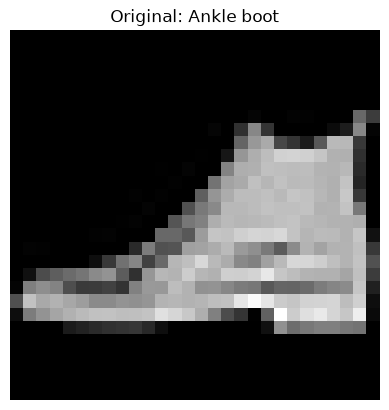

In [91]:
CATEGORIES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot",
]


def prepare_experiment(n_D=500, k=10, seed=42):
    """Build D from any image except the randomly chosen test target y."""

    train, train_labels, test, test_labels = load_fashion_mnist(
        "Lab 2 material/fashion_all.tar.gz"
    )

    images = np.concatenate((train, test), axis=0)  # (70000, 784), uint8
    labels = np.concatenate((train_labels, test_labels))
    rng = np.random.default_rng(seed)

    target_idx = len(train) + rng.integers(len(test))  # target is from test split
    y = images[target_idx].astype(np.float64) / 255.0  # (784,)

    # Sample from the full dataset without selecting the target itself.
    if not (1 <= n_D < len(images)):
        raise ValueError("n_D must satisfy 1 <= n_D < 70000")

    if not (0 <= k <= n_D):
        raise ValueError("k must satisfy 0 <= k <= n_D")

    pool = np.arange(len(images))
    pool = pool[pool != target_idx]
    selected = rng.choice(pool, size=n_D, replace=False)

    D = images[selected].T.astype(np.float64) / 255.0  # (784, n_D)

    # Normalize dictionary atoms to avoid favoring brighter images.
    norms = np.linalg.norm(D, axis=0)

    if np.any(norms == 0):
        raise ValueError("A sampled image is all black; resample the dictionary")

    D /= norms

    return D, y, int(labels[target_idx])


n_D, k = 500, 10  # user-defined lab parameters

D, y, label = prepare_experiment(n_D=n_D, k=k)

print(f"Dictionary D shape: {D.shape}")
print(f"Image y shape: {y.shape}")
print(f"Chosen test image: {CATEGORIES[label]}")
print(f"Sparsity limit k: {k}")

plt.imshow(y.reshape(28, 28), cmap="gray", vmin=0, vmax=1)
plt.title(f"Original: {CATEGORIES[label]}")
plt.axis("off")
plt.show()

Number of nonzero coefficients: 10
Reconstruction error: 3.521153837893921


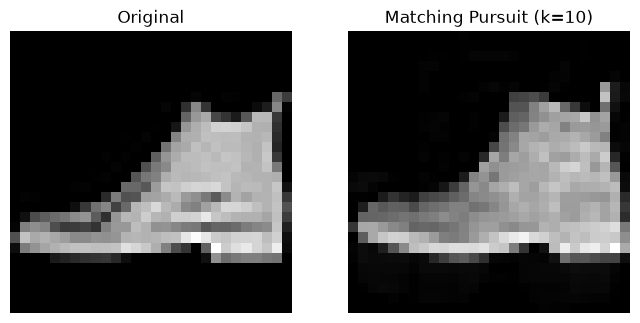

In [92]:
def mp(D, y, k):
    x = np.zeros(n_D)
    r = y.copy()
    selected = []

    for i in range(k):
        correlations = D.T @ r

        correlations[selected] = 0

        j = np.argmax(np.abs(correlations))

        if abs(correlations[j]) < 1e-10:
            break

        x[j] = correlations[j]
        selected.append(j)

        r = r - x[j] * D[:, j]

        if np.linalg.norm(r) < 1e-10:
            break

    return x

x_mp = mp(D, y, k)

y_mp = D @ x_mp

print("Number of nonzero coefficients:", np.count_nonzero(x_mp))
print("Reconstruction error:", np.linalg.norm(y - y_mp))

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(y.reshape(28, 28), cmap="gray", vmin=0, vmax=1)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(y_mp.reshape(28, 28), cmap="gray", vmin=0, vmax=1)
plt.title("Matching Pursuit (k=10)")
plt.axis("off")

plt.show()

Number of nonzero coefficients: 10
Reconstruction error: 2.7652363249360516


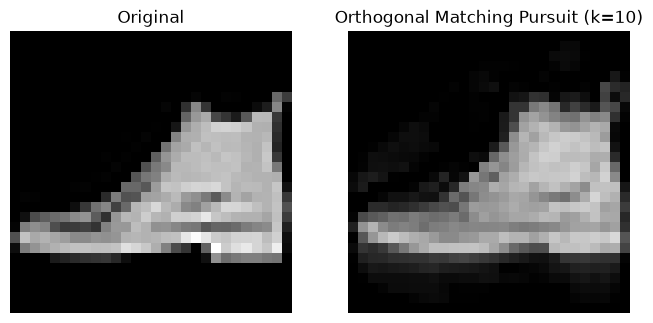

In [93]:

def omp(D, y, k):
    n_D = D.shape[1]

    x = np.zeros(n_D)
    r = y.copy()
    selected = []

    for i in range(k):
        correlations = D.T @ r

        scores = np.abs(correlations)
        scores[selected] = -np.inf

        j = np.argmax(scores)

        if scores[j] < 1e-10:
            break

        selected.append(j)

        D_selected = D[:, selected]

        coefficients, _, _, _ = np.linalg.lstsq(
            D_selected, y, rcond=None
        )

        r = y - D_selected @ coefficients

        if np.linalg.norm(r) < 1e-10:
            break

    x[selected] = coefficients if selected else []

    return x

x_omp = omp(D, y, k)

y_omp = D @ x_omp

print("Number of nonzero coefficients:", np.count_nonzero(x_omp))
print("Reconstruction error:", np.linalg.norm(y - y_omp))

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(y.reshape(28, 28), cmap="gray", vmin=0, vmax=1)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(y_omp.reshape(28, 28), cmap="gray", vmin=0, vmax=1)
plt.title("Orthogonal Matching Pursuit (k=10)")
plt.axis("off")

plt.show()

In [94]:
# Ex 3
from scipy.linalg import svd
from scipy.sparse import issparse
from scipy.sparse.linalg import svds
from scipy.io import loadmat

def cur(X, k, epsilon=0.8, mode="top", seed=None):
    n, p = X.shape

    if not 1 <= k <= min(n, p):
        raise ValueError("Invalid target rank")
    if epsilon <= 0:
        raise ValueError("epsilon must be positive")

    if k < min(n, p):
        Uk, _, Vtk = svds(X, k=k, which="LM")
    else:
        X_dense = X.toarray() if issparse(X) else X
        Uk, _, Vtk = svd(X_dense, full_matrices=False)

    col_scores = np.sum(Vtk[:k, :] ** 2, axis=0) / k
    row_scores = np.sum(Uk[:, :k] ** 2, axis=1) / k

    c = max(1, int(np.ceil(k * np.log(k) / epsilon**2)))
    c = min(c, p)
    r = min(c, n)

    rng = np.random.default_rng(seed)

    def select(scores, count):
        if mode == "top":
            indices = np.argsort(-scores)[:count]

        elif mode == "random":
            probs = np.maximum(scores, 1e-15)
            probs /= probs.sum()
            indices = rng.choice(
                len(scores),
                size=count,
                replace=False,
                p=probs
            )
            indices = indices[np.argsort(-scores[indices])]

        else:
            raise ValueError("Unknown selection mode")

        return indices

    col_idx = select(col_scores, c)
    row_idx = select(row_scores, r)

    C = X[:, col_idx]
    R = X[row_idx, :]

    if issparse(C):
        C = C.toarray()
    if issparse(R):
        R = R.toarray()

    U = np.linalg.pinv(C) @ (X @ np.linalg.pinv(R))

    return C, U, R

In [95]:
A = loadmat("A_med.mat")["A_med"]

print("Matrix shape:", A.shape)
print("Sparse matrix:", issparse(A))

C, U, R = cur(A, k=50, epsilon=0.8)

A_approx = C @ U @ R

# Convert A to dense for the error calculation
A_dense = A.toarray() if issparse(A) else A

relative_error = (
    np.linalg.norm(A_dense - A_approx, "fro")
    / np.linalg.norm(A_dense, "fro")
)

print("Relative Frobenius error:", relative_error)

Matrix shape: (5735, 1033)
Sparse matrix: True
Relative Frobenius error: 0.6246716949411852


/var/folders/sy/50gk3zw177g4529p4qy2310c0000gp/T/ipykernel_3500/3496989936.py:1: DeprecationWarning: The default value for `spmatrix` is changing to `False` in v1.20.
        That means the default return type will be a sparse array.
        Unless you use * instead of @, ** for matrix power, or you depend
        on 2D shapes from e.g. `A.sum(axis=0)` it may not matter to you.
        See the spmatrix to sparray migration guide for details.
        https://docs.scipy.org/doc/scipy/reference/sparse.migration_to_sparray.html
        
  A = loadmat("A_med.mat")["A_med"]


Optimal rank-50 error: 0.7891
CUR error: 0.6247
epsilon=0.8, c=306, error=0.6247
epsilon=0.9, c=242, error=0.6762
epsilon=1.0, c=196, error=0.7165
epsilon=1.1, c=162, error=0.7480
epsilon=1.2, c=136, error=0.7746


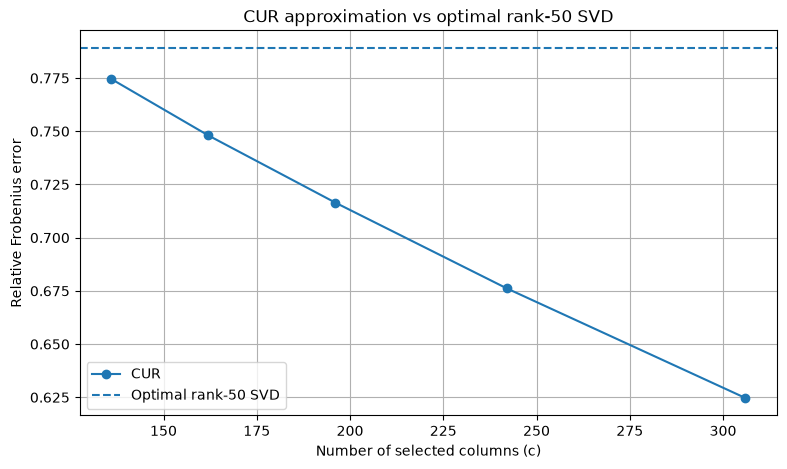

In [96]:
s = svds(A, k=50, return_singular_vectors=False)

norm_A = np.linalg.norm(A_dense, "fro")

# Frobenius error from the discarded singular values
optimal_error = np.sqrt(
    max(0, norm_A**2 - np.sum(s**2))
) / norm_A

print(f"Optimal rank-50 error: {optimal_error:.4f}")
print(f"CUR error: {relative_error:.4f}")

epsilons = [0.8, 0.9, 1.0, 1.1, 1.2]
cur_errors = []
num_columns = []

for eps in epsilons:
    C, U, R = cur(A, k=50, epsilon=eps)

    error = np.linalg.norm(
        A_dense - C @ U @ R, "fro"
    ) / norm_A

    cur_errors.append(error)
    num_columns.append(C.shape[1])

    print(f"epsilon={eps:.1f}, c={C.shape[1]}, error={error:.4f}")

plt.figure(figsize=(9, 5))

plt.plot(num_columns, cur_errors, "o-", label="CUR")
plt.axhline(
    optimal_error,
    linestyle="--",
    label="Optimal rank-50 SVD"
)

plt.xlabel("Number of selected columns (c)")
plt.ylabel("Relative Frobenius error")
plt.title("CUR approximation vs optimal rank-50 SVD")
plt.legend()
plt.grid(True)
plt.show()

In [97]:
C, U, R = cur(A, k=10, epsilon=0.8, mode="top")

print("C shape:", C.shape)
print("U shape:", U.shape)
print("R shape:", R.shape)

C shape: (5735, 36)
U shape: (36, 36)
R shape: (36, 1033)


C shape: (5735, 36)
U shape: (36, 36)
R shape: (36, 1033)
Dictionary variables: dict_keys(['__header__', '__version__', '__globals__', 'dict_med'])
Number of words: 5735
First 10 words: ['14th', '17b', '18th', '19th', '1st', '22nd', '2nd', '3rd', '4th', '5th']


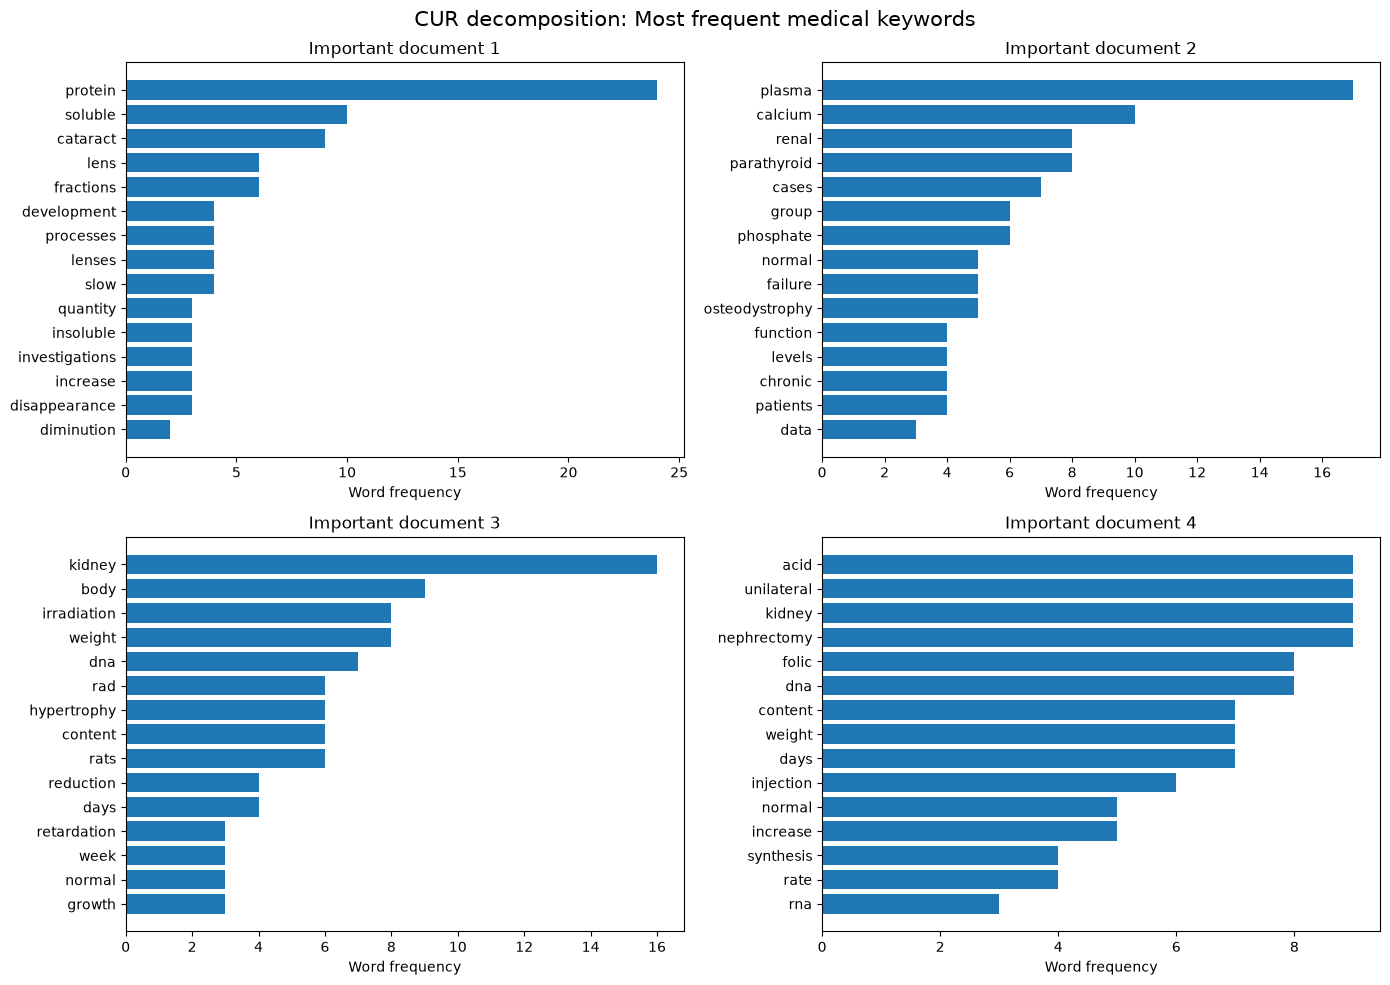

In [99]:
C, U, R = cur(A, k=10, epsilon=0.8, mode="top")

print("C shape:", C.shape)
print("U shape:", U.shape)
print("R shape:", R.shape)

dict_data = loadmat("dict_med.mat", squeeze_me=True)

print("Dictionary variables:", dict_data.keys())

word_key = next(
    key for key in dict_data
    if not key.startswith("__")
)

raw_words = np.asarray(dict_data[word_key]).ravel()

def decode_word(w):
    if isinstance(w, np.ndarray):
        w = w.item() if w.size == 1 else "".join(map(str, w.ravel()))
    if isinstance(w, bytes):
        w = w.decode("utf-8")
    return str(w).strip()

words = [decode_word(w) for w in raw_words]

print("Number of words:", len(words))
print("First 10 words:", words[:10])

assert len(words) == A.shape[0], "Dictionary size mismatch"

num_documents = 4
top_n = 15

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for j in range(num_documents):

    document = C[:, j]

    top_indices = np.argsort(document)[::-1][:top_n]

    top_words = [words[i] for i in top_indices]
    frequencies = document[top_indices]

    axes[j].barh(top_words[::-1], frequencies[::-1])
    axes[j].set_title(f"Important document {j + 1}")
    axes[j].set_xlabel("Word frequency")

plt.suptitle(
    "CUR decomposition: Most frequent medical keywords",
    fontsize=15
)
plt.tight_layout()
plt.show()
